# Prototype 00 : Baseline Diffusion Test

## Goal : Establish a stable diffusion in 2D.

Without any problematic and complex mechanisms like collagen concentration, EGFR phosphorylation, or any others, we can define our diffusion baseline and make sure the 2D architecture produces our desired result and is numerically stable.

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Tissue dimensions (cm)
Lx = 0.01
Ly = 0.02

# Number of cells
Nx = 51
Ny = 51

# Cell dimensions
dx = Lx / Nx
dy = Ly / Ny

# Cell-center coordinates
x = (np.arange(Nx) + 0.5) * dx
y = (np.arange(Ny) + 0.5) * dy

# Coordinate matrices
X, Y = np.meshgrid(x, y, indexing="ij")

print("Grid shape:", X.shape)
print(f"dx = {dx:.6e} cm")
print(f"dy = {dy:.6e} cm")

Grid shape: (51, 51)
dx = 1.960784e-04 cm
dy = 3.921569e-04 cm


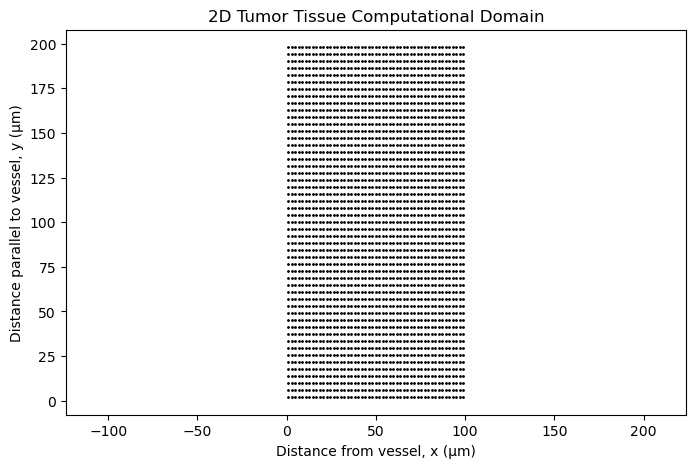

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(X * 1e4, Y * 1e4, "k.", markersize=2)

plt.xlabel("Distance from vessel, x (μm)")
plt.ylabel("Distance parallel to vessel, y (μm)")
plt.title("2D Tumor Tissue Computational Domain")

plt.axis("equal")
plt.show()

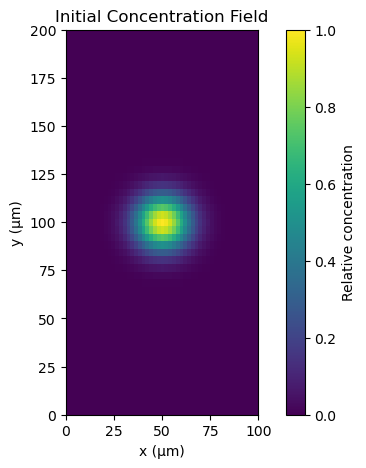

In [13]:
# Baseline diffusivity
D = 5e-7  # cm^2/s

# Initial concentration
x0 = Lx / 2
y0 = Ly / 2
sigma = 0.001  # cm

C = np.exp(
    -((X - x0)**2 + (Y - y0)**2) / (2 * sigma**2)
)

plt.figure(figsize=(7, 5))

plt.imshow(
    C.T,
    origin="lower",
    extent=[0, Lx * 1e4, 0, Ly * 1e4],
    aspect="equal"
)

plt.colorbar(label="Relative concentration")
plt.xlabel("x (μm)")
plt.ylabel("y (μm)")
plt.title("Initial Concentration Field")

plt.show()

In [14]:
def diffusion_step(C, D, dx, dy, dt):

    Nx, Ny = C.shape

    # ----------------------------------
    # Fluxes in the x direction
    # ----------------------------------

    # Fx[i, j] represents flux through an x-face
    # There are Nx + 1 faces
    Fx = np.zeros((Nx + 1, Ny))

    # Internal x-face fluxes
    Fx[1:-1, :] = -D * (
        C[1:, :] - C[:-1, :]
    ) / dx

    # Closed boundaries: zero outward flux
    Fx[0, :] = 0
    Fx[-1, :] = 0


    # ----------------------------------
    # Fluxes in the y direction
    # ----------------------------------

    # Fy[i, j] represents flux through a y-face
    # There are Ny + 1 faces
    Fy = np.zeros((Nx, Ny + 1))

    # Internal y-face fluxes
    Fy[:, 1:-1] = -D * (
        C[:, 1:] - C[:, :-1]
    ) / dy

    # Periodic boundary between last and first cells
    periodic_flux = -D * (
        C[:, 0] - C[:, -1]
    ) / dy

    Fy[:, 0] = periodic_flux
    Fy[:, -1] = periodic_flux


    # ----------------------------------
    # Calculate divergence of flux
    # ----------------------------------

    divergence_x = (
        Fx[1:, :] - Fx[:-1, :]
    ) / dx

    divergence_y = (
        Fy[:, 1:] - Fy[:, :-1]
    ) / dy

    divergence = divergence_x + divergence_y


    # ----------------------------------
    # Update concentration
    # ----------------------------------

    C_new = C - dt * divergence

    return C_new

In [15]:
dt_max = 1 / (
    2 * D * (1/dx**2 + 1/dy**2)
)

dt = 0.01

print(f"Maximum stable timestep: {dt_max:.6f} s")
print(f"Chosen timestep: {dt:.6f} s")

assert dt < dt_max, "Timestep is too large!"

Maximum stable timestep: 0.030757 s
Chosen timestep: 0.010000 s


In [16]:
T = 60
Nt = int(T / dt)

save_times = [0, 1, 5, 15, 30, 60]

saved_C = {0: C.copy()}

for step in range(1, Nt + 1):

    C = diffusion_step(C, D, dx, dy, dt)

    t = step * dt

    if step in [int(target / dt) for target in save_times]:
        saved_C[int(round(t))] = C.copy()

print("Simulation complete.")

Simulation complete.


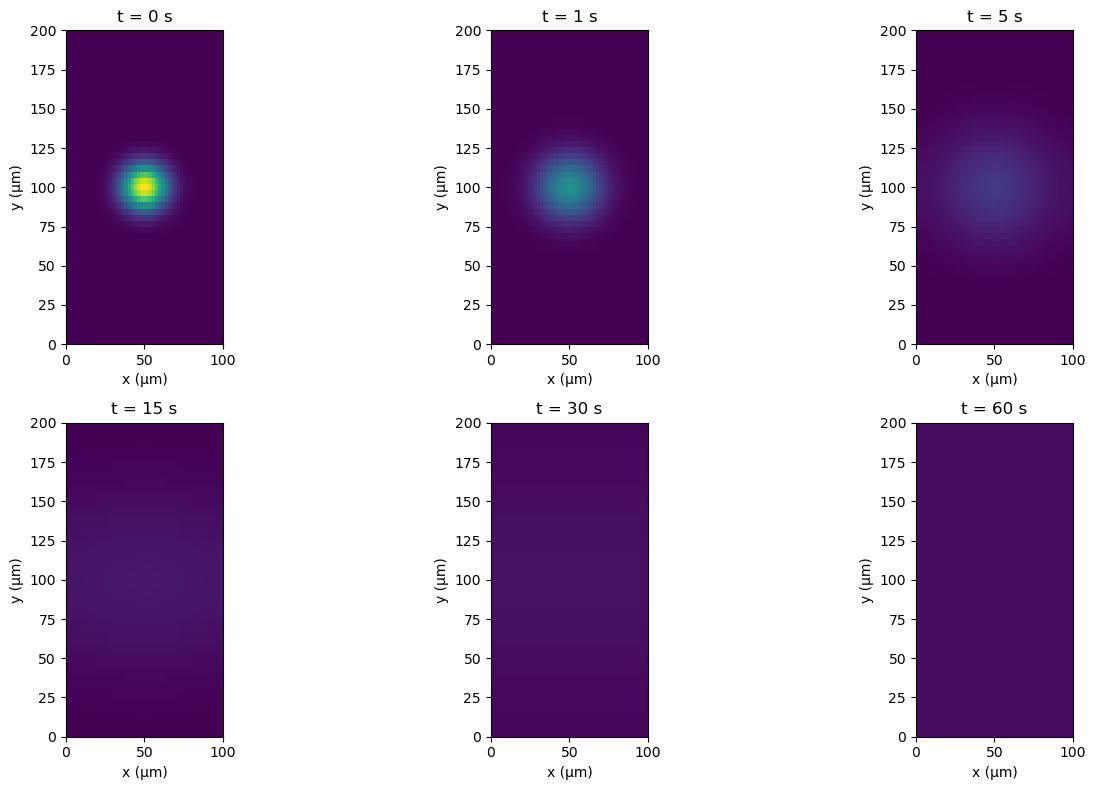

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, t in zip(axes.flat, save_times):

    ax.imshow(
        saved_C[t].T,
        origin="lower",
        extent=[0, Lx * 1e4, 0, Ly * 1e4],
        aspect="equal",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"t = {t} s")
    ax.set_xlabel("x (μm)")
    ax.set_ylabel("y (μm)")

plt.tight_layout()
plt.show()

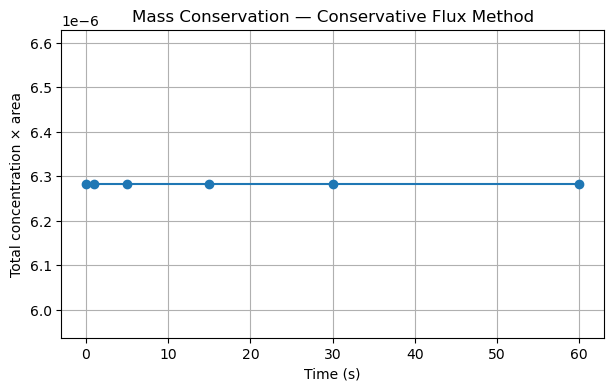

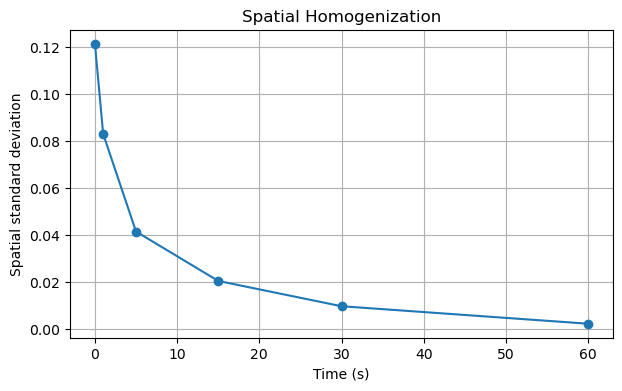

In [18]:
mass_values = []
mean_values = []
std_values = []

for t in save_times:

    field = saved_C[t]

    mass_values.append(np.sum(field) * dx * dy)
    mean_values.append(np.mean(field))
    std_values.append(np.std(field))


# Mass plot
plt.figure(figsize=(7, 4))

plt.plot(save_times, mass_values, marker="o")

plt.xlabel("Time (s)")
plt.ylabel("Total concentration × area")
plt.title("Mass Conservation — Conservative Flux Method")
plt.grid(True)

plt.show()


# Spatial variation plot
plt.figure(figsize=(7, 4))

plt.plot(save_times, std_values, marker="o")

plt.xlabel("Time (s)")
plt.ylabel("Spatial standard deviation")
plt.title("Spatial Homogenization")
plt.grid(True)

plt.show()

In [19]:
initial_mass = mass_values[0]
final_mass = mass_values[-1]

relative_mass_error = abs(final_mass - initial_mass) / initial_mass

print(f"Initial mass: {initial_mass:.12e}")
print(f"Final mass:   {final_mass:.12e}")
print(f"Relative error: {relative_mass_error:.12e}")

assert relative_mass_error < 1e-10, "Mass conservation test failed!"

print("Mass conservation test PASSED.")

Initial mass: 6.283181851027e-06
Final mass:   6.283181851027e-06
Relative error: 4.044286640132e-16
Mass conservation test PASSED.
